# Lab 03 — Supervised learning II: model families

*Neighbors, naive Bayes, trees, ensembles and support vector machines on one workflow*

**Goal.** Compare model families under Lab 2's fixed validation workflow on a hard, real credit problem: see the boundary each family draws, read a tree's rules and watch it overfit, check whether ensembles earn their cost, and tune an SVM's two dials.

**Data.** `all_datasets/supervised/lending_club/lending_club_2014_2015.zip`, `all_datasets/supervised/used_cars/used_cars.zip`, and `all_datasets/supervised/sms_spam/sms_spam.csv` for the Try-it

**Reading.** Chapters 11 to 14: nearest neighbors and naive Bayes, decision trees, ensembles, support vector machines.

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab03_supervised_models/lab03_supervised_models_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab03_supervised_models/lab03_supervised_models_worked.py`.

**Evidence.** `results/lab03/` — the k search, the loan tree's rules, the car-price fold scores, the SVM grid, `metrics.csv` and the figures

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Rank loan defaults with KNN and naive Bayes; draw their boundaries | 2–5 |
| B | Read a small tree's rules, then watch a deep tree overfit | 6–8 |
| C | Compare a forest with boosting on used-car prices | 9–10 |
| D | Tune an SVM, map its two dials, save and verify it | 11–13 |
| Finish | Save the evidence; then classify text messages as spam | 14–16 |
| After | Your-turn tasks, expected findings, troubleshooting and the two checklists (on the lab sheet) | — |

## Setup

Imports and paths. `start_lab()`, from `all_experiments/course_setup.py`, finds the course folder by looking upward for `all_datasets/`; figures and tables go to `results/lab03/`, and the saved SVM to `models/`.

### Question 1 — Setup

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab

# 2. The libraries this lab uses.
import joblib                                                      # save and load fitted models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, mean_absolute_error, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
# the model families compared in this lab
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
# turning text into word counts, for the Try-it
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 3. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab03")

course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab03/ and models/


## Part A — Neighbors and naive Bayes

**Goal.** Rank loan defaults with two simple model families, and see why accuracy hides the difference.

*Questions 2–5 · Data: Lending Club loans, 2014 and 2015*

### Question 2 — Read the loans and split them

Lending Club, a US lender, published every loan it made. This table holds 100,000 loans issued in 2014 and 2015 that have finished: `loan_status` says whether each was paid in full or charged off, written off as a default. The cell builds thirteen numbers the lender knew when it approved the loan, such as the interest rate, the term, the income and the FICO credit score; the data card's eight columns written after the loan was issued never enter a model. A random 20,000 loans keep nearest neighbors and SVMs fast on a laptop, and `stratify` keeps the default rate the same in both halves.

In [2]:
loans = pd.read_csv(DATA / "supervised/lending_club/lending_club_2014_2015.zip", low_memory=False)
print("shape:", loans.shape)
print(loans["loan_status"].value_counts().to_string())

# Thirteen numbers the lender knew when it approved the loan. The eight columns written after
# the loan was issued (payments, recoveries, the latest credit score) never enter a model.
issued = pd.to_datetime(loans["issue_d"], format="%b-%Y")
first_credit = pd.to_datetime(loans["earliest_cr_line"], format="%b-%Y")
X_all = pd.DataFrame({
    "loan_amnt": loans["loan_amnt"],
    "term_months": loans["term"].str.extract(r"(\d+)")[0].astype(int),          # " 36 months" -> 36
    "int_rate": loans["int_rate"],
    "log_income": np.log1p(loans["annual_inc"]),                                # incomes run into the millions
    "dti": loans["dti"],
    "fico": (loans["fico_range_low"] + loans["fico_range_high"]) / 2,
    "revol_util": loans["revol_util"],
    "inquiries_6m": loans["inq_last_6mths"],
    "delinq_2y": loans["delinq_2yrs"],
    "open_acc": loans["open_acc"],
    "mort_acc": loans["mort_acc"],
    "emp_years": loans["emp_length"].replace({"< 1 year": "0 years"}).str.extract(r"(\d+)")[0].astype(float),
    "credit_years": (issued - first_credit).dt.days / 365.25,                   # length of the credit history
})
y_all = (loans["loan_status"] == "Charged Off").astype(int)
print("missing values:", X_all.isna().sum()[lambda s: s > 0].to_dict())

# A random 20,000 loans keep nearest neighbors and SVMs fast on a laptop; the other 80,000 wait for Part D.
X = X_all.sample(20_000, random_state=42)
y = y_all.loc[X.index]
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(len(X_train), "training and", len(X_valid), "validation loans;", int(y_valid.sum()), "validation defaults")

# Every model below fills the few gaps with the training median, then scales: one shared first half.
def prepare():
    return [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]

shape: (100000, 40)
loan_status
Fully Paid     80630
Charged Off    19370
missing values: {'dti': 1, 'revol_util': 39, 'emp_years': 5542}
15000 training and 5000 validation loans; 959 validation defaults


### Question 3 — Choose k by cross-validation

$k$ is chosen by five-fold cross-validation on the training rows only, scored by ROC AUC because accuracy says little when 81% of loans are repaid. The imputer and the scaler sit inside the pipeline, so each fold fills and scales with its own training rows.

k=   1  cross-validated ROC AUC = 0.552


k=   5  cross-validated ROC AUC = 0.632


k=  25  cross-validated ROC AUC = 0.692


k= 101  cross-validated ROC AUC = 0.710


k= 201  cross-validated ROC AUC = 0.716


k= 401  cross-validated ROC AUC = 0.717


k= 801  cross-validated ROC AUC = 0.719


k=1601  cross-validated ROC AUC = 0.718


k=3201  cross-validated ROC AUC = 0.717
selected k: 801


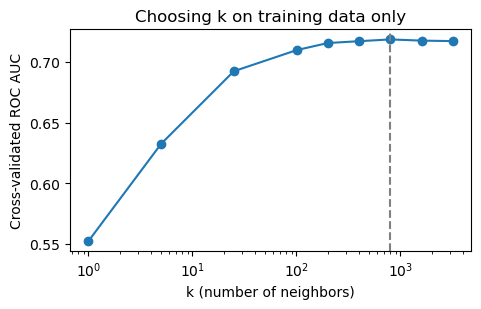

In [3]:
# Score each k with five-fold cross-validation on the training loans only.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
k_values = [1, 5, 25, 101, 201, 401, 801, 1601, 3201]
cv_scores = {}
for k in k_values:
    candidate = Pipeline(prepare() + [("model", KNeighborsClassifier(n_neighbors=k))])
    scores = cross_val_score(candidate, X_train, y_train, cv=cv, scoring="roc_auc")
    cv_scores[k] = scores.mean()
    print(f"k={k:4d}  cross-validated ROC AUC = {scores.mean():.3f}")

best_k = max(cv_scores, key=cv_scores.get)                       # the k with the highest score
print("selected k:", best_k)

plt.figure(figsize=(5, 3.2))
plt.plot(k_values, [cv_scores[k] for k in k_values], marker="o")
plt.xscale("log")
plt.axvline(best_k, linestyle="--", color="grey")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Cross-validated ROC AUC")
plt.title("Choosing k on training data only")
plt.tight_layout()
plt.savefig(RESULTS / "choosing_k_on_training_data_only.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 4 — Compare KNN with naive Bayes

The chosen KNN against Gaussian naive Bayes, with Lab 2's logistic regression as a reference, on the validation loans. Accuracy is printed only to show why it is the wrong metric here; average precision is the honest one for the rarer class.

In [4]:
models = {
    "KNN": Pipeline(prepare() + [("model", KNeighborsClassifier(n_neighbors=best_k))]),
    "GaussianNB": Pipeline(prepare() + [("model", GaussianNB())]),
    "logistic": Pipeline(prepare() + [("model", LogisticRegression(max_iter=2000))]),
}

print("always 'repaid' would be", round(1 - y_valid.mean(), 3), "accurate")
for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_valid)[:, 1]                     # each loan's predicted chance of default
    accuracy = accuracy_score(y_valid, prob >= 0.5)
    auc = roc_auc_score(y_valid, prob)
    ap = average_precision_score(y_valid, prob)
    print(f"{name:10s} accuracy={accuracy:.3f} roc_auc={auc:.3f} average_precision={ap:.3f}")

always 'repaid' would be 0.808 accurate


KNN        accuracy=0.808 roc_auc=0.723 average_precision=0.379
GaussianNB accuracy=0.773 roc_auc=0.716 average_precision=0.350
logistic   accuracy=0.811 roc_auc=0.731 average_precision=0.387


### Question 5 — Draw the boundaries on two columns

Two columns only, the interest rate and the debt-to-income ratio, so the boundary can be drawn. Shading is each model's predicted default probability, crosses are real defaults. Each family has its own shape: logistic regression draws straight bands, naive Bayes curved ones, and KNN follows the data.

Logistic regression    on interest rate and DTI only: ROC AUC 0.714


KNN (k=801)            on interest rate and DTI only: ROC AUC 0.714


Gaussian naive Bayes   on interest rate and DTI only: ROC AUC 0.712


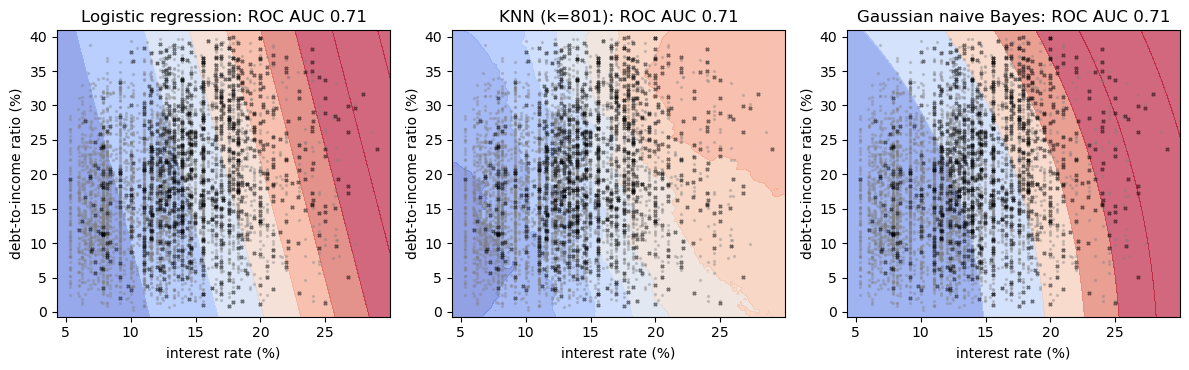

In [5]:
# Three model families on just two columns, so their decision boundaries can be drawn.
two = ["int_rate", "dti"]
families = {
    "Logistic regression": LogisticRegression(max_iter=2000),
    f"KNN (k={best_k})": KNeighborsClassifier(n_neighbors=best_k),
    "Gaussian naive Bayes": GaussianNB(),
}
repaid = (y_valid == 0).to_numpy()
shown = X_valid[two].fillna(X_train[two].median())                # the plot needs every point filled

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (name, estimator) in zip(axes, families.items()):
    small = Pipeline(prepare() + [("model", estimator)])
    small.fit(X_train[two], y_train)
    auc = roc_auc_score(y_valid, small.predict_proba(X_valid[two])[:, 1])
    print(f"{name:22s} on interest rate and DTI only: ROC AUC {auc:.3f}")
    # Shade each point of the plane by its predicted chance of default, then add the real loans on top.
    DecisionBoundaryDisplay.from_estimator(small, shown, ax=ax, response_method="predict_proba",
                                           cmap="coolwarm", alpha=0.6, vmin=0, vmax=0.6)
    ax.scatter(shown.loc[repaid, two[0]], shown.loc[repaid, two[1]], s=2, color="grey", alpha=0.3)
    ax.scatter(shown.loc[~repaid, two[0]], shown.loc[~repaid, two[1]], s=5, color="black", marker="x", alpha=0.5)
    ax.set_title(f"{name}: ROC AUC {auc:.2f}")
    ax.set_xlabel("interest rate (%)")
    ax.set_ylabel("debt-to-income ratio (%)")
plt.tight_layout()
plt.savefig(RESULTS / "three_boundaries_on_rate_and_dti.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** 19,370 of the 100,000 loans were charged off; in the 5,000 validation loans, always answering *repaid* is already 80.8% accurate, which is why every score below is ROC AUC or average precision. Cross-validated ROC AUC climbs with $k$ from 0.552 at $k=1$ to 0.719 at $k=801$, then levels off: one borrower's nearest neighbor says almost nothing about them, but the default rate among 801 similar borrowers does. On the validation loans KNN scores ROC AUC 0.723 and average precision 0.379, naive Bayes 0.716 and 0.350, and logistic regression 0.731 and 0.387. All three are close, and accuracy barely moves from the baseline. On two columns the three families draw three different shapes and score the same, 0.71: on noisy credit data the data, not the algorithm, sets the ceiling.

**Checkpoint: before you move on**

- 959 validation defaults, so always saying “repaid” is already 0.808 accurate.
- KNN reaches ROC AUC 0.723 and average precision 0.379; naive Bayes 0.716 and 0.350.

## Part B — One tree: readable rules and overfitting

**Goal.** Fit a tree small enough to read, see what it learned about lending, then watch a deeper tree overfit.

*Questions 6–8 · Data: Lending Club loans*

### Question 6 — Fit a readable tree

A tree needs no scaling, but scikit-learn's trees need every gap filled, so the training median fills them first. A depth-3 tree has at most eight leaves: few enough to read. Watch how many loans it flags at the usual 0.5 cutoff.

In [6]:
# Trees need no scaling, but scikit-learn's trees need every gap filled: the training median again.
filler = SimpleImputer(strategy="median").set_output(transform="pandas").fit(X_train)
Xt_train, Xt_valid = filler.transform(X_train), filler.transform(X_valid)

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(Xt_train, y_train)
prob_tree = tree.predict_proba(Xt_valid)[:, 1]
print("validation ROC AUC:", round(roc_auc_score(y_valid, prob_tree), 3),
      " average precision:", round(average_precision_score(y_valid, prob_tree), 3))
print("loans flagged at 0.5:", int((prob_tree >= 0.5).sum()))
leaf_rates = np.unique(prob_tree.round(3))
print("default rate in each leaf:", leaf_rates.tolist())

validation ROC AUC: 0.715  average precision: 0.338
loans flagged at 0.5: 0
default rate in each leaf: [0.055, 0.097, 0.149, 0.209, 0.244, 0.292, 0.344, 0.475]


### Question 7 — Read the tree's rules

A depth-3 tree is a set of if-then rules small enough to print. `show_weights` adds, for each leaf, how many training loans were repaid and how many defaulted, so each rule comes with its own default rate. Ask which columns the tree chose, and who chose those columns' values.

|--- int_rate <= 14.0
|   |--- int_rate <= 10.3
|   |   |--- int_rate <= 7.9
|   |   |   |--- weights: [2260.0, 131.0] class: 0
|   |   |--- int_rate >  7.9
|   |   |   |--- weights: [2158.0, 231.0] class: 0
|   |--- int_rate >  10.3
|   |   |--- term_months <= 48.0
|   |   |   |--- weights: [3309.0, 581.0] class: 0
|   |   |--- term_months >  48.0
|   |   |   |--- weights: [663.0, 214.0] class: 0
|--- int_rate >  14.0
|   |--- term_months <= 48.0
|   |   |--- int_rate <= 17.7
|   |   |   |--- weights: [1728.0, 457.0] class: 0
|   |   |--- int_rate >  17.7
|   |   |   |--- weights: [506.0, 209.0] class: 0
|   |--- term_months >  48.0
|   |   |--- mort_acc <= 1.5
|   |   |   |--- weights: [709.0, 641.0] class: 0
|   |   |--- mort_acc >  1.5
|   |   |   |--- weights: [789.0, 414.0] class: 0



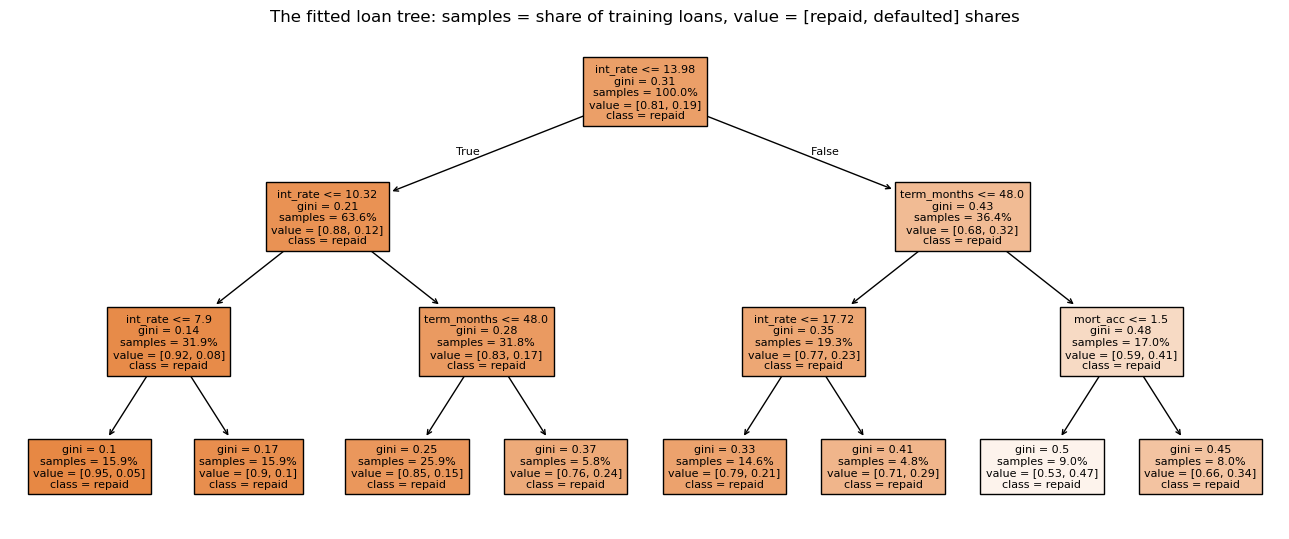

In [7]:
# The fitted tree as if-then rules; weights are the training loans in each leaf: [repaid, defaulted].
feature_names = list(Xt_train.columns)
rules = export_text(tree, feature_names=feature_names, show_weights=True, decimals=1)
print(rules)

plt.figure(figsize=(13, 5.5))
plot_tree(tree, feature_names=feature_names, class_names=["repaid", "defaulted"], filled=True, fontsize=8,
          proportion=True, precision=2)
plt.title("The fitted loan tree: samples = share of training loans, value = [repaid, defaulted] shares")
plt.tight_layout()
plt.savefig(RESULTS / "the_fitted_loan_tree.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 8 — Grow the tree and watch it overfit

The same tree with ten depth limits, scored by average precision on the training and validation rows. Deeper trees can always fit the training rows better; the question is when validation stops agreeing.

max_depth=   1  leaves=   2  training AP=0.266  validation AP=0.265
max_depth=   2  leaves=   4  training AP=0.317  validation AP=0.310
max_depth=   3  leaves=   8  training AP=0.344  validation AP=0.338
max_depth=   4  leaves=  16  training AP=0.363  validation AP=0.350
max_depth=   5  leaves=  31  training AP=0.388  validation AP=0.349
max_depth=   6  leaves=  55  training AP=0.415  validation AP=0.345
max_depth=   8  leaves= 156  training AP=0.497  validation AP=0.331


max_depth=  10  leaves= 376  training AP=0.604  validation AP=0.297
max_depth=  15  leaves=1289  training AP=0.873  validation AP=0.244
max_depth=None  leaves=2408  training AP=1.000  validation AP=0.226


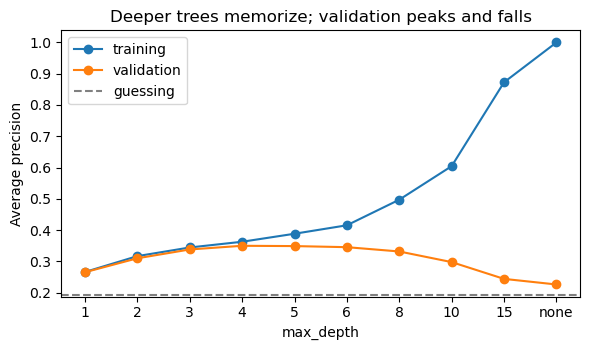

In [8]:
# Grow the same tree deeper and deeper; None means "no limit".
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, None]
train_ap, valid_ap = [], []
for depth in depths:
    t = DecisionTreeClassifier(max_depth=depth, random_state=42)
    t.fit(Xt_train, y_train)
    train_ap.append(average_precision_score(y_train, t.predict_proba(Xt_train)[:, 1]))
    valid_ap.append(average_precision_score(y_valid, t.predict_proba(Xt_valid)[:, 1]))
    print(f"max_depth={str(depth):>4}  leaves={t.get_n_leaves():4d}  "
          f"training AP={train_ap[-1]:.3f}  validation AP={valid_ap[-1]:.3f}")

labels = [str(d) if d else "none" for d in depths]
plt.figure(figsize=(6, 3.6))
plt.plot(labels, train_ap, marker="o", label="training")
plt.plot(labels, valid_ap, marker="o", label="validation")
plt.axhline(y_valid.mean(), linestyle="--", color="grey", label="guessing")
plt.xlabel("max_depth")
plt.ylabel("Average precision")
plt.title("Deeper trees memorize; validation peaks and falls")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "deeper_trees_memorize_validation_peaks_and_falls.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** The depth-3 tree scores validation ROC AUC 0.715 and average precision 0.338, and it flags no loan at all at 0.5: no leaf has more defaults than repayments. Its value is in the ranking, from a 5.5% default rate in the safest leaf to 47.5% in the riskiest. Its rules read like a credit policy and use almost nothing but the interest rate and the term: a rate above 14.0% on a 60-month loan is the riskiest branch. The interest rate is the price the lender set from its own risk grade, so on that column the tree has largely learned the lender's assessment back. Grown deeper, it overfits: training average precision rises to 1.000 for the unrestricted tree with 2,408 leaves, while validation peaks at 0.350 at depth 4 and falls to 0.226, little above the 0.192 that guessing scores.

**Checkpoint: before you move on**

- The depth-3 tree flags no loan at 0.5, yet ranks them with ROC AUC 0.715; its leaves run from 5.5% to 47.5% default.
- Validation average precision peaks at depth 4 (0.350), while training keeps climbing to 1.000.

## Part C — Many trees: forest against boosting

**Goal.** Compare two tree ensembles on Lab 2's used-car prices, and see which features they rely on.

*Questions 9–10 · Data: used-car listings from Cars.com*

### Question 9 — Compare forest and boosting on car prices

Back to Lab 2's car listings, with the same cleaning rules, the log of the price as the label, and the car's `model` included this time. Trees split on numbers, so each category becomes a code; a tree can still isolate a make or a model with a few splits. The boosting model is scikit-learn's histogram-based gradient boosting, the fast version built for tables with many rows. Three folds give three scores per family, so the gap between the families can be compared with the spread within each one.

random_forest      CV log-RMSE = 0.2083 +/- 0.0014   folds [0.2086 0.21   0.2065]


gradient_boosting  CV log-RMSE = 0.1941 +/- 0.0008   folds [0.1945 0.1947 0.193 ]


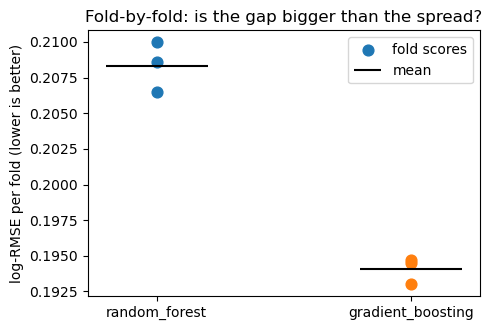

In [9]:
cars = pd.read_csv(DATA / "supervised/used_cars/used_cars.zip", low_memory=False)

# Lab 2's fixed rules: used cars, a believable price, a real odometer reading, tidy spellings.
used = cars[(cars["stock_type"] == "Used") & cars["price_usd"].between(1_000, 200_000)
            & (cars["mileage_miles"] > 100)].copy()

def tidy(column, groups):
    """Each group is matched by a pattern in the lower-case text; the first match wins, no match becomes a gap."""
    text = column.str.lower()
    matches = [text.str.contains(pattern, na=False) for pattern in groups.values()]
    return pd.Series(np.select(matches, list(groups), default=None), index=column.index)

used["drive"] = tidy(used["drivetrain"], {"AWD": "all|awd", "4WD": "four|4wd|4x4", "FWD": "front|fwd", "RWD": "rear|rwd"})
used["fuel_type"] = tidy(used["fuel"], {"plug-in hybrid": "plug", "hybrid": "hybrid|mild", "electric": "electric",
                                        "diesel": "diesel", "flex fuel": "flex|e85", "gasoline": "gas|petrol|unleaded"})
used["age"] = (2026 - used["year"]).clip(lower=0)

# Trees split on numbers, so each category becomes a code (Toyota = 68, say); a gap gets the code -1.
c_num = ["age", "mileage_miles", "cpo"]
c_cat = ["make", "model", "body_type", "drive", "fuel_type"]
codes = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1)
X_c = pd.concat([used[c_num].reset_index(drop=True),
                 pd.DataFrame(codes.fit_transform(used[c_cat]), columns=c_cat)], axis=1)
y_c = np.log(used["price_usd"]).reset_index(drop=True)      # the log price, as in Lab 2's Try-it

ensembles = {
    "random_forest": RandomForestRegressor(n_estimators=150, max_features=0.5, min_samples_leaf=2,
                                           random_state=42, n_jobs=-1),
    "gradient_boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, random_state=42),
}

# Three folds; scikit-learn reports the negative mean squared error, so flip the sign and take the root.
cv3 = KFold(n_splits=3, shuffle=True, random_state=42)
cv_rmse = {}
for name, estimator in ensembles.items():
    neg_mse = cross_val_score(estimator, X_c, y_c, cv=cv3, scoring="neg_mean_squared_error")
    cv_rmse[name] = np.sqrt(-neg_mse)
    print(f"{name:18s} CV log-RMSE = {cv_rmse[name].mean():.4f} +/- {cv_rmse[name].std():.4f}"
          f"   folds {np.round(cv_rmse[name], 4)}")

plt.figure(figsize=(5, 3.4))
for i, (name, values) in enumerate(cv_rmse.items()):
    plt.scatter([i] * len(values), values, s=60, label="fold scores" if i == 0 else None)
    plt.hlines(values.mean(), i - 0.2, i + 0.2, color="black", label="mean" if i == 0 else None)
plt.xticks(range(len(cv_rmse)), list(cv_rmse))
plt.ylabel("log-RMSE per fold (lower is better)")
plt.title("Fold-by-fold: is the gap bigger than the spread?")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "fold_by_fold_is_the_gap_bigger_than_the_spread.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 10 — See what the boosted trees used

One boosted model on a 75/25 split, scored in dollars, then permutation importance: shuffle one column on the validation rows and measure how much worse the predictions get.

validation MAE in dollars: 4453  R2 in dollars: 0.843


age              0.357
mileage_miles    0.323
make             0.219
model            0.147
drive            0.084
body_type        0.052
fuel_type        0.010
cpo              0.001


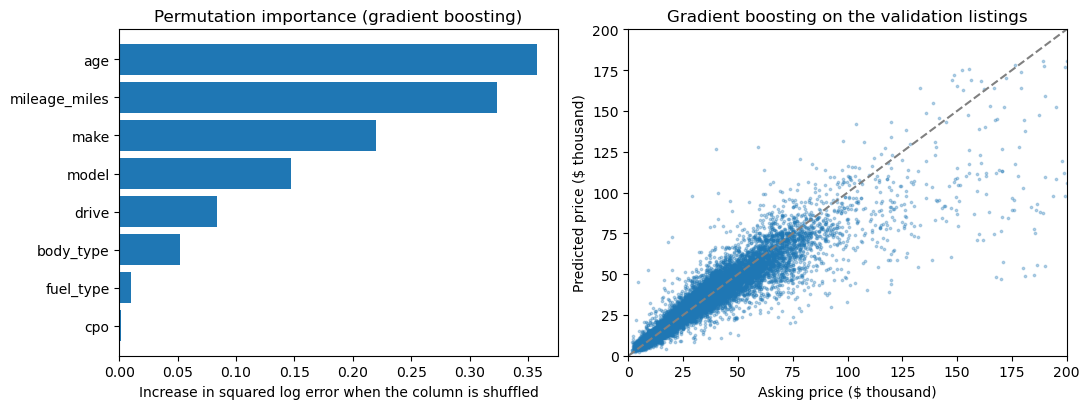

In [10]:
Xc_train, Xc_valid, yc_train, yc_valid = train_test_split(X_c, y_c, test_size=0.25, random_state=42)
booster = ensembles["gradient_boosting"].fit(Xc_train, yc_train)

# Back from log prices to dollars, then score the predictions in dollars.
price_pred = np.exp(booster.predict(Xc_valid))
price_true = np.exp(yc_valid)
squared_misses = ((price_true - price_pred) ** 2).sum()
squared_spread = ((price_true - price_true.mean()) ** 2).sum()
r2_dollars = 1 - squared_misses / squared_spread
print("validation MAE in dollars:", round(mean_absolute_error(price_true, price_pred)),
      " R2 in dollars:", round(r2_dollars, 3))

# Shuffle one column at a time and measure how much worse the predictions get.
importance = permutation_importance(booster, Xc_valid, yc_valid, n_repeats=5, random_state=42, n_jobs=-1)
ranked = pd.Series(importance.importances_mean, index=X_c.columns).sort_values()
print(ranked.sort_values(ascending=False).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].barh(ranked.index, ranked.values)
axes[0].set_xlabel("Increase in squared log error when the column is shuffled")
axes[0].set_title("Permutation importance (gradient boosting)")
axes[1].scatter(price_true / 1e3, price_pred / 1e3, s=3, alpha=0.3)
axes[1].plot([0, 200], [0, 200], linestyle="--", color="grey")
axes[1].set_xlim(0, 200)
axes[1].set_ylim(0, 200)
axes[1].set_xlabel("Asking price ($ thousand)")
axes[1].set_ylabel("Predicted price ($ thousand)")
axes[1].set_title("Gradient boosting on the validation listings")
plt.tight_layout()
plt.savefig(RESULTS / "what_the_boosted_trees_used.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** Boosting beats the forest on every fold, with a log-RMSE of 0.1941 against 0.2083, and the gap is ten times either family's spread across folds. On a 75/25 split the boosted trees miss a typical listing by \$4,453 and explain 84.3% of the variation in price, against Lab 2's straight line at \$9,009 and 57.5%. Age and mileage matter most, then the make and the model: the trees found how a car loses value, and which car it is, without a single hand-made feature.

**Checkpoint: before you move on**

- Cross-validated log-RMSE: 0.2083 for the forest, 0.1941 for boosting.
- Boosting misses a typical listing by \$4,453, with $R^2$ 0.843 in dollars; age and mileage matter most.

## Part D — Support vector machines

**Goal.** Tune an SVM's two dials by cross-validation, test it once on loans no part has seen, then save the model and check that it reloads.

*Questions 11–13 · Data: Lending Club loans*

### Question 11 — Tune an SVM

Back to the loans. Parts A and B compared models on the validation loans, so the test set is 20,000 of the 80,000 loans outside the sample, which no part has touched. The grid crosses a linear kernel with two values of `C`, and an RBF kernel with three of `C` and three of `gamma`, scored by three-fold ROC AUC on the training loans. Balanced class weights stop the SVM from calling every loan repaid.

In [11]:
# Parts A and B compared models on the validation loans, so the test set must be loans no part has seen:
# 20,000 of the 80,000 loans outside the sample. The SVM trains on Part A's training loans.
outside = X_all.drop(X.index)
X_test = outside.sample(20_000, random_state=1)
y_test = y_all.loc[X_test.index]

# Two dials: C (how hard to fit the training loans) and gamma (how local the RBF kernel is).
# Balanced class weights stop the SVM from simply calling every loan "repaid".
svm_pipe = Pipeline(prepare() + [("model", SVC(class_weight="balanced"))])
search = GridSearchCV(
    svm_pipe,
    param_grid=[
        {"model__kernel": ["linear"], "model__C": [0.1, 1]},
        {"model__kernel": ["rbf"], "model__C": [0.1, 1, 10], "model__gamma": ["scale", 0.01, 0.1]},
    ],
    cv=StratifiedKFold(3, shuffle=True, random_state=42),
    scoring="roc_auc",
    n_jobs=-1,
)
search.fit(X_train, y_train)

score = search.decision_function(X_test)          # distance from the boundary: higher means more likely to default
pred = search.predict(X_test)                     # the decision at the boundary itself
print("best parameters:", search.best_params_)
print("cross-validated ROC AUC:", round(search.best_score_, 3))
print("test ROC AUC:", round(roc_auc_score(y_test, score), 3),
      " test average precision:", round(average_precision_score(y_test, score), 3))
print("at the default boundary: precision", round(precision_score(y_test, pred), 3),
      " recall", round(recall_score(y_test, pred), 3))

best parameters: {'model__C': 0.1, 'model__gamma': 0.01, 'model__kernel': 'rbf'}
cross-validated ROC AUC: 0.718
test ROC AUC: 0.716  test average precision: 0.375
at the default boundary: precision 0.34  recall 0.543


### Question 12 — Map the two dials

The RBF part of the grid as a heatmap, then two small SVMs on the interest rate and the debt-to-income ratio alone, drawn so the difference between the kernels is visible.

gamma            0.01    0.1  scale
param_model__C                     
0.1             0.718  0.713  0.714
1.0             0.715  0.702  0.707
10.0            0.714  0.647  0.665


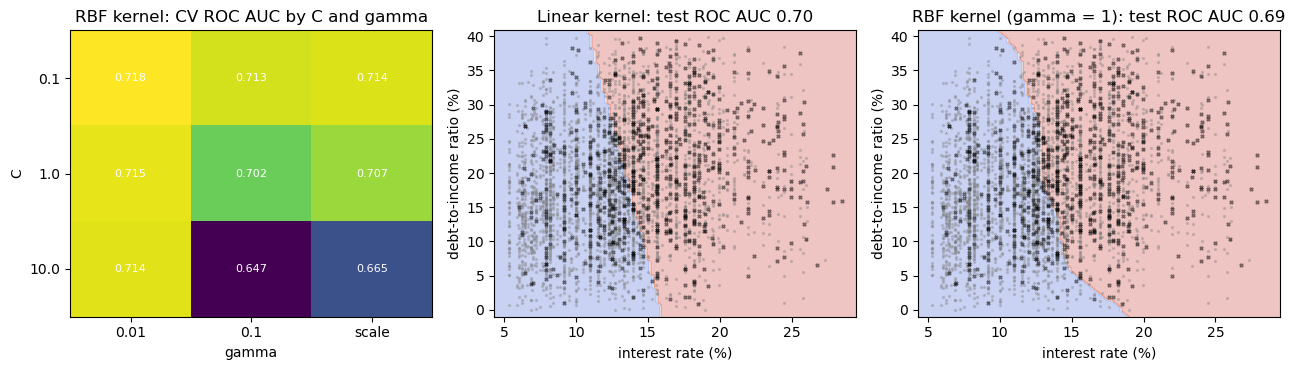

In [12]:
# The RBF rows of the search, as a table of C against gamma.
results = pd.DataFrame(search.cv_results_)
rbf = results[results["param_model__kernel"] == "rbf"].copy()
rbf["gamma"] = rbf["param_model__gamma"].astype(str)
grid = rbf.pivot(index="param_model__C", columns="gamma", values="mean_test_score")
print(grid.round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].imshow(grid.values, cmap="viridis", aspect="auto")
axes[0].set_xticks(range(len(grid.columns)), grid.columns)
axes[0].set_yticks(range(len(grid.index)), grid.index)
axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        axes[0].text(j, i, f"{grid.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)
axes[0].set_title("RBF kernel: CV ROC AUC by C and gamma")

# Two-column versions, drawn so the difference between the kernels is visible.
kernels = {
    "Linear kernel": SVC(kernel="linear", C=1, class_weight="balanced"),
    "RBF kernel (gamma = 1)": SVC(kernel="rbf", C=1, gamma=1.0, class_weight="balanced"),
}
defaulted = (y_test == 1).to_numpy()
drawn = X_test[two].fillna(X_train[two].median()).iloc[:4000]          # 4,000 test loans keep the plot readable
for ax, (title, estimator) in zip(axes[1:], kernels.items()):
    small = Pipeline(prepare() + [("model", estimator)])
    small.fit(X_train[two], y_train)
    auc = roc_auc_score(y_test, small.decision_function(X_test[two]))
    DecisionBoundaryDisplay.from_estimator(small, drawn, ax=ax, alpha=0.3, response_method="predict", cmap="coolwarm")
    ax.scatter(drawn.loc[~defaulted[:4000], two[0]], drawn.loc[~defaulted[:4000], two[1]], s=2, color="grey", alpha=0.3)
    ax.scatter(drawn.loc[defaulted[:4000], two[0]], drawn.loc[defaulted[:4000], two[1]], s=5, color="black",
               marker="x", alpha=0.5)
    ax.set_title(f"{title}: test ROC AUC {auc:.2f}")
    ax.set_xlabel("interest rate (%)")
    ax.set_ylabel("debt-to-income ratio (%)")
plt.tight_layout()
plt.savefig(RESULTS / "two_dials_and_two_kernels.png", dpi=160, bbox_inches="tight")
plt.show()

### Question 13 — Save and verify the model

Save the winning pipeline and check that the file reproduces the test predictions exactly before calling it done.

In [13]:
# Save the tuned pipeline (imputer, scaler and SVM together), load it back, and check it predicts the same.
model_path = MODELS / "loan_default_svm.joblib"
joblib.dump(search.best_estimator_, model_path)
loaded = joblib.load(model_path)
same = np.array_equal(loaded.predict(X_test), pred)
print("file size (KB):", round(model_path.stat().st_size / 1024, 1))
print("reloaded model reproduces the test predictions:", same)

file size (KB): 1393.0
reloaded model reproduces the test predictions: True


**What the output shows.** The grid picks an RBF kernel with `C = 0.1` and `gamma = 0.01`, a smooth and heavily regularized boundary, at a cross-validated ROC AUC of 0.718; on the 20,000 test loans it scores 0.716, with average precision 0.375. Its balanced boundary flags enough loans to catch 54.3% of the defaults, at a precision of 0.34. A wiggly kernel does worse: `gamma = 0.1` with `C = 10` is the worst cell of the heatmap, 0.647. On two columns, the linear and the RBF kernels score 0.70 and 0.69: a curved boundary has nothing to follow here. The saved file is large, 1,393 KB, because an SVM keeps its support vectors, and on noisy data that is most of the training loans. It reproduces the test predictions exactly.

**Checkpoint: before you move on**

- Best: RBF kernel, `C` = 0.1, `gamma` = 0.01; cross-validated ROC AUC 0.718, test 0.716.
- The reloaded model reproduces the test predictions.

## Evidence

Write the numbers above to the results folder. These files are regenerated on every run; do not edit them by hand.

### Question 14 — Save the evidence

In [14]:
pd.Series(cv_scores, name="cv_roc_auc").rename_axis("k").round(4).to_csv(RESULTS / "knn_selection.csv")
(RESULTS / "loan_tree_rules.txt").write_text(rules)
pd.DataFrame(cv_rmse).round(4).to_csv(RESULTS / "car_price_fold_scores.csv", index=False)
grid_columns = ["param_model__kernel", "param_model__C", "param_model__gamma", "mean_test_score", "std_test_score",
                "rank_test_score"]
results[grid_columns].sort_values("rank_test_score").round(4).to_csv(RESULTS / "svm_grid_search.csv", index=False)

# One row per model, collected from the parts above.
rows = []
for name, m in models.items():
    rows.append({"part": "A", "dataset": "lending_club", "model": name, "metric": "roc_auc",
                 "validation": roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1])})
rows.append({"part": "B", "dataset": "lending_club", "model": "decision_tree(depth=3)", "metric": "average_precision",
             "validation": average_precision_score(y_valid, prob_tree)})
for name, values in cv_rmse.items():
    rows.append({"part": "C", "dataset": "used_cars", "model": name, "metric": "cv_log_rmse",
                 "validation": values.mean()})
rows.append({"part": "D", "dataset": "lending_club", "model": f"svc {search.best_params_}", "metric": "roc_auc",
             "validation": search.best_score_, "test": roc_auc_score(y_test, score)})
pd.DataFrame(rows).round(4).to_csv(RESULTS / "metrics.csv", index=False)
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['car_price_fold_scores.csv', 'choosing_k_on_training_data_only.png', 'deeper_trees_memorize_validation_peaks_and_falls.png', 'fold_by_fold_is_the_gap_bigger_than_the_spread.png', 'knn_selection.csv', 'loan_tree_rules.txt', 'metrics.csv', 'svm_grid_search.csv', 'the_fitted_loan_tree.png', 'three_boundaries_on_rate_and_dti.png', 'two_dials_and_two_kernels.png', 'what_the_boosted_trees_used.png']


## Try it yourself

Naive Bayes is famous for text. Load `supervised/sms_spam/sms_spam.csv`, turn each message into word counts with `CountVectorizer`, and compare `MultinomialNB` with a nearest-neighbor classifier on tf-idf vectors. Report ROC AUC, precision and recall, and list the words that most raise the spam odds.

Attempt it in the cell below before reading the solution.

### Question 15 — Try it yourself

In [15]:
# Your work here

### One solution

The same split-fit-score workflow, with a vectorizer in front of each model. The vectorizer learns its vocabulary from the training messages only, because it sits inside the pipeline.

### Question 16 — One solution

In [16]:
sms = pd.read_csv(DATA / "supervised/sms_spam/sms_spam.csv")
y_s = (sms["label"] == "spam").astype(int)
print("messages:", len(sms), " spam share:", round(y_s.mean(), 3),
      " repeated messages:", int(sms["message"].duplicated().sum()))
Xs_train, Xs_valid, ys_train, ys_valid = train_test_split(sms["message"], y_s, test_size=0.25, random_state=42,
                                                          stratify=y_s)

# Each pipeline turns the messages into word columns first, then classifies them.
text_models = {
    "naive Bayes on word counts": Pipeline([
        ("words", CountVectorizer()),                     # one column per word: how often it appears
        ("model", MultinomialNB()),
    ]),
    "KNN (k=5) on tf-idf, cosine": Pipeline([
        ("words", TfidfVectorizer()),                     # word counts, down-weighting very common words
        ("model", KNeighborsClassifier(5, metric="cosine")),
    ]),
}
for name, model in text_models.items():
    model.fit(Xs_train, ys_train)
    p = model.predict_proba(Xs_valid)[:, 1]
    print(f"{name:28s} ROC AUC={roc_auc_score(ys_valid, p):.3f}  precision={precision_score(ys_valid, p >= 0.5):.3f}  "
          f"recall={recall_score(ys_valid, p >= 0.5):.3f}")

# Which words push a message towards spam? Compare each word's log probability in spam and in ham.
nb = text_models["naive Bayes on word counts"]
vocab = nb.named_steps["words"].get_feature_names_out()
word_log_prob = nb.named_steps["model"].feature_log_prob_          # row 0: ham, row 1: spam
log_ratio = word_log_prob[1] - word_log_prob[0]
top_ten = np.argsort(log_ratio)[-10:][::-1]
print("words that most raise the spam odds:", list(vocab[top_ten]))

messages: 5572  spam share: 0.134  repeated messages: 403
naive Bayes on word counts   ROC AUC=0.982  precision=0.988  recall=0.909


KNN (k=5) on tf-idf, cosine  ROC AUC=0.973  precision=0.987  recall=0.824
words that most raise the spam odds: ['claim', 'prize', '150p', 'tone', 'cs', '500', 'guaranteed', '18', '1000', 'landline']


**What it shows.** 5,572 messages, 13.4% spam, and 403 exact repeats, which a careful project would drop before splitting. Naive Bayes on word counts scores ROC AUC 0.982, precision 0.988 and recall 0.909; the neighbor model on tf-idf scores 0.973, 0.987 and 0.824. Naive Bayes wins on text, and it trains in an instant: its *naive* assumption that words are independent is false, but it is a good enough approximation when there are thousands of weak clues. The words that most raise the spam odds are claim, prize, 150p, tone, cs, 500, guaranteed, 18, 1000 and landline, the vocabulary of a premium-rate scam.